# Customer Behaviour & Churn Analysis

**Objective:** understand who the customers are, how they buy, and how many are slipping away, so the business knows where to focus retention.

**Data:** 500 customers from five Indian cities (`customer_data.csv`): age, gender, city, signup and last purchase dates, purchase amount (₹), feedback score (1–5), product category and payment method. The dataset is synthetic; some names and genders don't match, so gender results are treated as illustrative.

**Approach:** clean the data → describe each variable → look at purchase timing → segment customers by recency → findings.

In [1]:
import pandas as pd

## 1. Load and clean the data

Age, purchase amount and feedback score each have 25 missing values (5%). Age and feedback are filled with the mean; purchase amount with the median, because spend is less sensitive to outliers that way. There are no duplicate rows.

In [2]:
df = pd.read_csv('customer_data.csv')
df.head()

,User_ID,Name,Age,Gender,City,Signup_Date,Last_Purchase_Date,Purchase_Amount,Feedback_Score,Product_Category,Payment_Method
0,1001,Priya Verma,NaN,Male,Bangalore,2022-06-19,2022-07-13,4819.26,3.2,Home Decor,UPI
1,1002,Rahul Verma,46.0,Female,Kolkata,2023-06-30,2024-04-18,2792.69,2.5,Home Decor,UPI
2,1003,Ankit Sen,32.0,Male,Bangalore,2023-02-18,2023-02-22,4832.53,NaN,Groceries,Cash on Delivery
3,1004,Arjun Das,25.0,Male,Delhi,2022-09-08,2023-04-16,2219.24,1.4,Electronics,Card
4,1005,Rahul Gupta,38.0,Male,Mumbai,2024-01-29,2025-01-27,1627.90,2.7,Home Decor,Cash on Delivery


In [3]:
df.isnull().sum()

User_ID                0
Name                   0
Age                   25
Gender                 0
City                   0
Signup_Date            0
Last_Purchase_Date     0
Purchase_Amount       25
Feedback_Score        25
Product_Category       0
Payment_Method         0
dtype: int64

In [4]:
df['Age'] = df['Age'].fillna(df['Age'].mean())

In [5]:
df['Purchase_Amount'] = df['Purchase_Amount'].fillna(df['Purchase_Amount'].median())

In [6]:
df.drop_duplicates(inplace=True)

In [7]:
df['Feedback_Score'].isnull().sum()

np.int64(25)

In [8]:
df['Feedback_Score'] = df['Feedback_Score'].fillna(df['Feedback_Score'].mean())

In [9]:
df.head()

,User_ID,Name,Age,Gender,City,Signup_Date,Last_Purchase_Date,Purchase_Amount,Feedback_Score,Product_Category,Payment_Method
0,1001,Priya Verma,39.187368,Male,Bangalore,2022-06-19,2022-07-13,4819.26,3.200,Home Decor,UPI
1,1002,Rahul Verma,46.000000,Female,Kolkata,2023-06-30,2024-04-18,2792.69,2.500,Home Decor,UPI
2,1003,Ankit Sen,32.000000,Male,Bangalore,2023-02-18,2023-02-22,4832.53,2.956,Groceries,Cash on Delivery
3,1004,Arjun Das,25.000000,Male,Delhi,2022-09-08,2023-04-16,2219.24,1.400,Electronics,Card
4,1005,Rahul Gupta,38.000000,Male,Mumbai,2024-01-29,2025-01-27,1627.90,2.700,Home Decor,Cash on Delivery


In [10]:
df['Feedback_Score'] = df['Feedback_Score'].round(2)

In [11]:
df.head()

,User_ID,Name,Age,Gender,City,Signup_Date,Last_Purchase_Date,Purchase_Amount,Feedback_Score,Product_Category,Payment_Method
0,1001,Priya Verma,39.187368,Male,Bangalore,2022-06-19,2022-07-13,4819.26,3.20,Home Decor,UPI
1,1002,Rahul Verma,46.000000,Female,Kolkata,2023-06-30,2024-04-18,2792.69,2.50,Home Decor,UPI
2,1003,Ankit Sen,32.000000,Male,Bangalore,2023-02-18,2023-02-22,4832.53,2.96,Groceries,Cash on Delivery
3,1004,Arjun Das,25.000000,Male,Delhi,2022-09-08,2023-04-16,2219.24,1.40,Electronics,Card
4,1005,Rahul Gupta,38.000000,Male,Mumbai,2024-01-29,2025-01-27,1627.90,2.70,Home Decor,Cash on Delivery


In [12]:
df['Age'] = df['Age'].round().astype(int)

In [13]:
df.head()

,User_ID,Name,Age,Gender,City,Signup_Date,Last_Purchase_Date,Purchase_Amount,Feedback_Score,Product_Category,Payment_Method
0,1001,Priya Verma,39,Male,Bangalore,2022-06-19,2022-07-13,4819.26,3.20,Home Decor,UPI
1,1002,Rahul Verma,46,Female,Kolkata,2023-06-30,2024-04-18,2792.69,2.50,Home Decor,UPI
2,1003,Ankit Sen,32,Male,Bangalore,2023-02-18,2023-02-22,4832.53,2.96,Groceries,Cash on Delivery
3,1004,Arjun Das,25,Male,Delhi,2022-09-08,2023-04-16,2219.24,1.40,Electronics,Card
4,1005,Rahul Gupta,38,Male,Mumbai,2024-01-29,2025-01-27,1627.90,2.70,Home Decor,Cash on Delivery


In [14]:
df.dtypes

User_ID                 int64
Name                      str
Age                     int64
Gender                    str
City                      str
Signup_Date               str
Last_Purchase_Date        str
Purchase_Amount       float64
Feedback_Score        float64
Product_Category          str
Payment_Method            str
dtype: object

In [15]:
df['Feedback_Score'] = df['Feedback_Score'].round().astype(int)

## 2. Univariate analysis

Distributions of the numeric columns, then frequency counts for gender and city.

In [16]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
User_ID,500.0,1250.50000,144.481833,1001.00,1125.7500,1250.50,1375.250,1500.0
Age,500.0,39.17800,11.910080,18.00,29.0000,40.00,49.000,59.0
Purchase_Amount,500.0,2552.95098,1385.440651,115.77,1344.9125,2590.97,3713.145,4991.9
Feedback_Score,500.0,2.94400,1.184766,1.00,2.0000,3.00,4.000,5.0


In [17]:
# summary statistics for numerical column
numeric_cols = ['Age', 'Purchase_Amount', 'Feedback_Score']

summary = df[numeric_cols].describe().T
summary['median'] = df[numeric_cols].median()
summary['IQR'] = summary['75%'] - summary['25%']
summary['skewness'] = df[numeric_cols].skew()
print("Numeric Summary Statistics:\n")
summary

Numeric Summary Statistics:



,count,mean,std,min,25%,50%,75%,max,median,IQR,skewness
Age,500.0,39.17800,11.910080,18.00,29.0000,40.00,49.000,59.0,40.00,20.0000,-0.194545
Purchase_Amount,500.0,2552.95098,1385.440651,115.77,1344.9125,2590.97,3713.145,4991.9,2590.97,2368.2325,-0.044589
Feedback_Score,500.0,2.94400,1.184766,1.00,2.0000,3.00,4.000,5.0,3.00,2.0000,0.021488


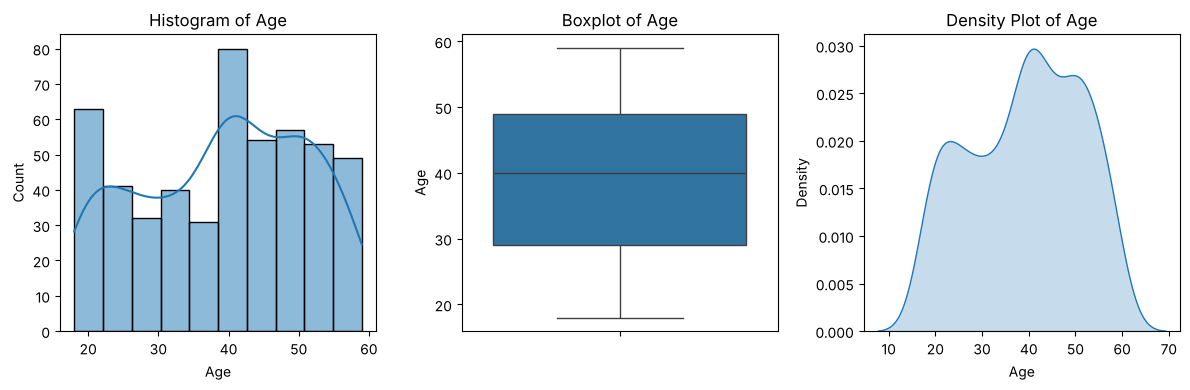

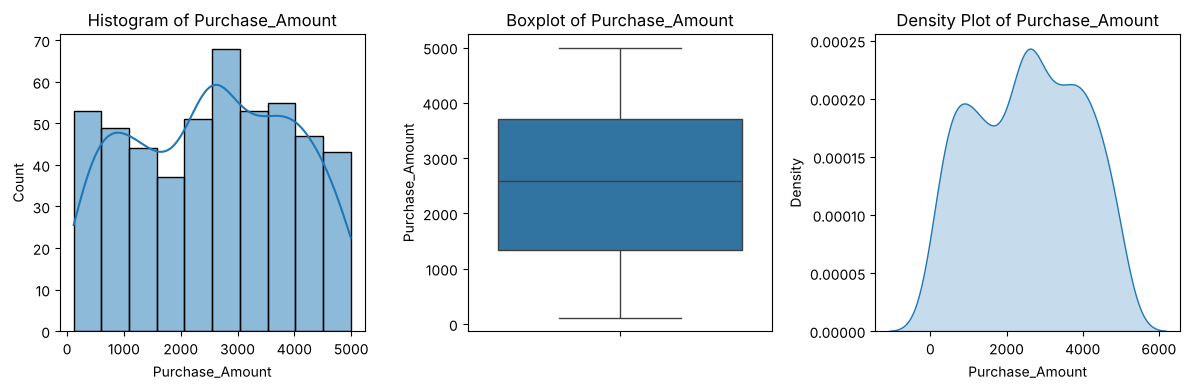

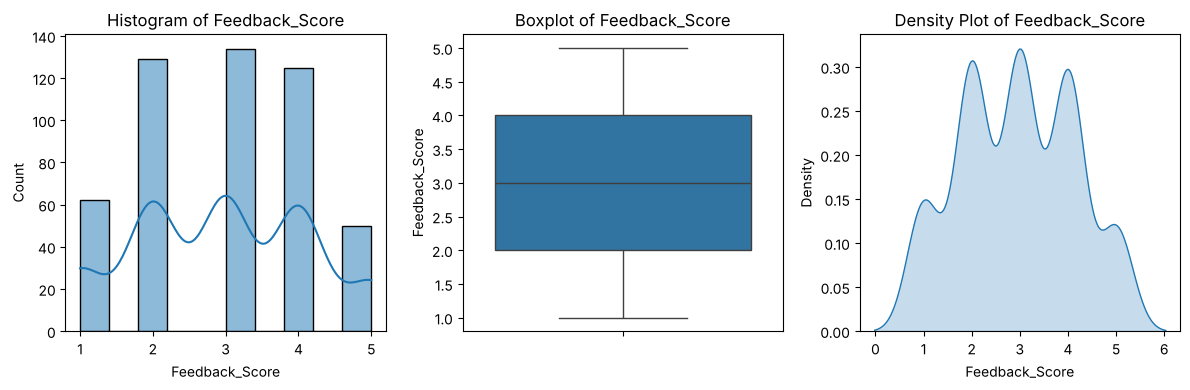

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns
# histogram, boxplot, density plot for numerical columns
for col in numeric_cols:
    plt.figure(figsize=(12,4))

    plt.subplot(1,3,1)
    sns.histplot(df[col], kde=True)
    plt.title(f'Histogram of {col}')

    plt.subplot(1,3,2)
    sns.boxplot(y=df[col])
    plt.title(f'Boxplot of {col}')

    plt.subplot(1,3,3)
    sns.kdeplot(df[col], fill=True)
    plt.title(f'Density Plot of {col}')

    plt.tight_layout()
    plt.show()


 Frequency counts for Gender:
 Gender
Male      271
Female    229
Name: count, dtype: int64


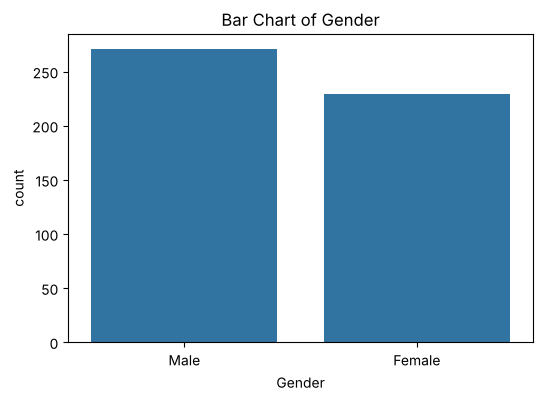


 Frequency counts for City:
 City
Mumbai       106
Kolkata      105
Delhi        101
Chennai       99
Bangalore     89
Name: count, dtype: int64


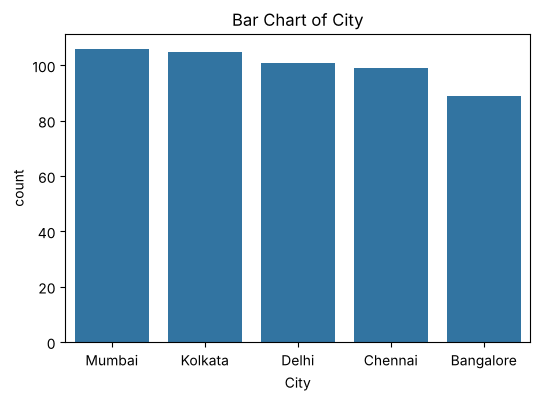

In [19]:
# Frequency count for categorical columns
cat_cols = ['Gender', 'City']

for index, col in enumerate(cat_cols):
    print(f"\n Frequency counts for {col}:\n", df[col].value_counts())
    plt.figure(figsize=(6,4))
    sns.countplot(x=col, data=df, order=df[col].value_counts().index)
    plt.title(f'Bar Chart of {col}')
    plt.show()

## 3. Purchase timing

Signups run from January 2022 to June 2024 and last purchases from January 2022 to May 2025. The charts below look at when purchases happen and whether there's a seasonal pattern.


 Date Range for Signup_Date: 2022-01-02 00:00:00 to 2024-06-18 00:00:00
Time span: 898 days

 Date Range for Last_Purchase_Date: 2022-01-31 00:00:00 to 2025-05-30 00:00:00
Time span: 1215 days


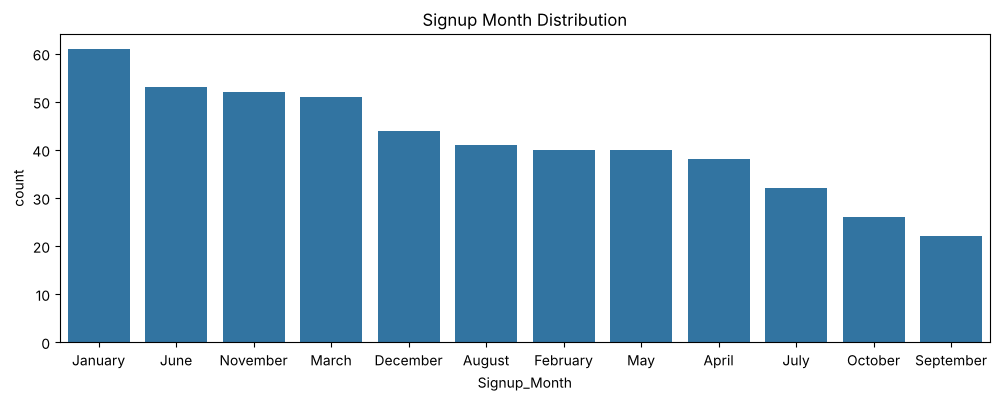

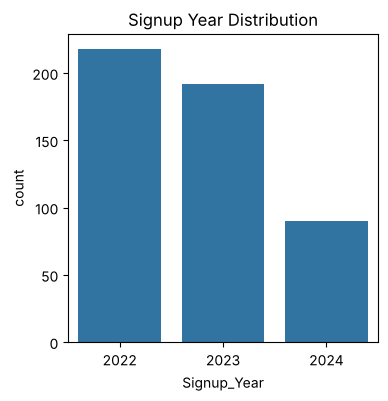

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

date_cols = ['Signup_Date', 'Last_Purchase_Date']

# Convert date columns to datetime objects
for col in date_cols:
    df[col] = pd.to_datetime(df[col])

for col in date_cols:
    print(f"\n Date Range for {col}: {df[col].min()} to {df[col].max()}")
    print(f"Time span: {(df[col].max() - df[col].min()).days} days")

# Month distribution
plt.figure(figsize = (12,4))
df['Signup_Month'] = df['Signup_Date'].dt.month_name()
sns.countplot(x='Signup_Month', data=df, order=df['Signup_Month'].value_counts().index)
plt.title('Signup Month Distribution')
plt.show()

# Year distribution
plt.figure(figsize = (4,4))
df['Signup_Year'] = df['Signup_Date'].dt.year
sns.countplot(x='Signup_Year', data=df)
plt.title('Signup Year Distribution')
plt.show()

In [21]:
def time_granularity(series):
    diffs = series.sort_values().diff().dropna().dt.days
    return diffs.describe()

In [22]:
time_granularity(df['Last_Purchase_Date'])

count    499.00000
mean       2.43487
std        3.08339
min        0.00000
25%        1.00000
50%        1.00000
75%        3.00000
max       28.00000
Name: Last_Purchase_Date, dtype: float64

In [23]:
df['Last_Purchase_Date'].sort_values().diff().value_counts()

Last_Purchase_Date
1 days     176
0 days      98
2 days      66
3 days      43
4 days      36
6 days      21
5 days      19
7 days      14
8 days       8
12 days      4
15 days      3
13 days      3
9 days       2
16 days      1
10 days      1
14 days      1
11 days      1
28 days      1
22 days      1
Name: count, dtype: int64

In [24]:
time_granularity(df['Signup_Date'])

count    499.000000
mean       1.799599
std        1.912735
min        0.000000
25%        1.000000
50%        1.000000
75%        2.000000
max       14.000000
Name: Signup_Date, dtype: float64

In [25]:
df['Signup_Date'].sort_values().diff().value_counts()

Signup_Date
1 days     159
0 days     120
2 days     100
3 days      52
4 days      26
5 days      14
6 days      10
8 days       8
7 days       6
9 days       2
11 days      1
14 days      1
Name: count, dtype: int64

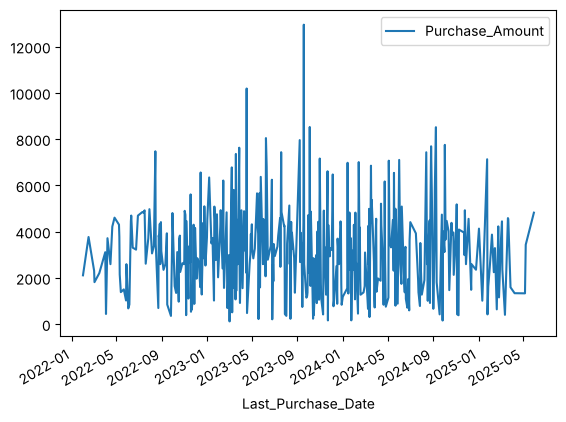

In [26]:
df.groupby('Last_Purchase_Date')[['Purchase_Amount']].sum().plot()
plt.show()

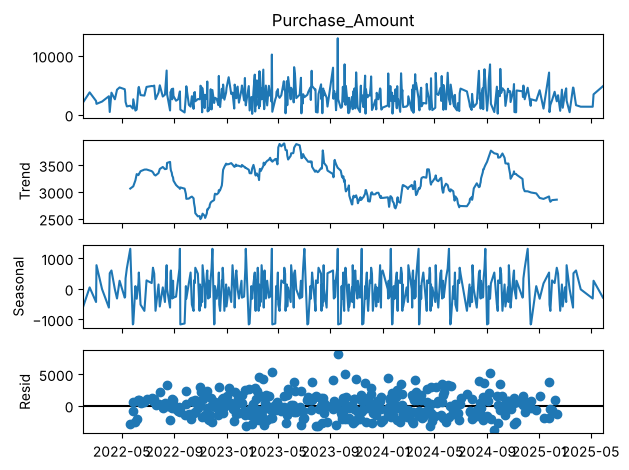

In [27]:
from statsmodels.tsa.seasonal import seasonal_decompose

df_daily = df.groupby('Last_Purchase_Date')['Purchase_Amount'].sum()
result = seasonal_decompose(df_daily, model='additive', period=30)
result.plot().show()

In [28]:
df["day"] = df["Last_Purchase_Date"].dt.day
df["month"] = df["Last_Purchase_Date"].dt.month
heatmap_data = df.pivot_table(
    index="day",
    columns="month",
    values="Purchase_Amount",
    aggfunc="mean"
)
heatmap_data

month,1,2,3,4,5,6,7,8,9,10,11,12
day,,,,,,,,,,,,
1,2849.815000,NaN,1547.875000,2253.500000,4314.680000,2911.227500,2204.750,1275.380000,662.370000,2992.540000,4897.6100,NaN
2,4128.310000,NaN,1996.710000,3940.580000,3217.270000,679.850000,2941.920,356.060000,NaN,3325.596667,4220.2700,3207.300000
3,NaN,1070.680000,1813.550000,2678.960000,1146.210000,NaN,NaN,NaN,NaN,2749.890000,2910.2025,1964.060000
4,NaN,4820.630000,NaN,NaN,2355.483333,2590.970000,NaN,3475.540000,3222.290000,3045.152500,763.1800,3655.580000
5,NaN,3168.730000,2802.913333,1971.500000,2842.800000,844.920000,NaN,3057.090000,2712.343333,2643.640000,386.9000,1981.934286
6,2113.586667,3813.676667,2356.640000,1553.020000,2459.305000,3808.080000,NaN,NaN,NaN,1652.130000,2224.5750,NaN
7,NaN,NaN,NaN,3713.790000,NaN,1903.215000,NaN,NaN,2652.006667,4662.545000,NaN,771.840000
8,NaN,NaN,2258.800000,1335.980000,3866.650000,2187.746667,NaN,1904.720000,2799.122500,NaN,383.1200,NaN
9,NaN,NaN,584.020000,NaN,3516.860000,4444.360000,3358.430,NaN,3828.850000,1347.890000,2253.1150,1252.980000


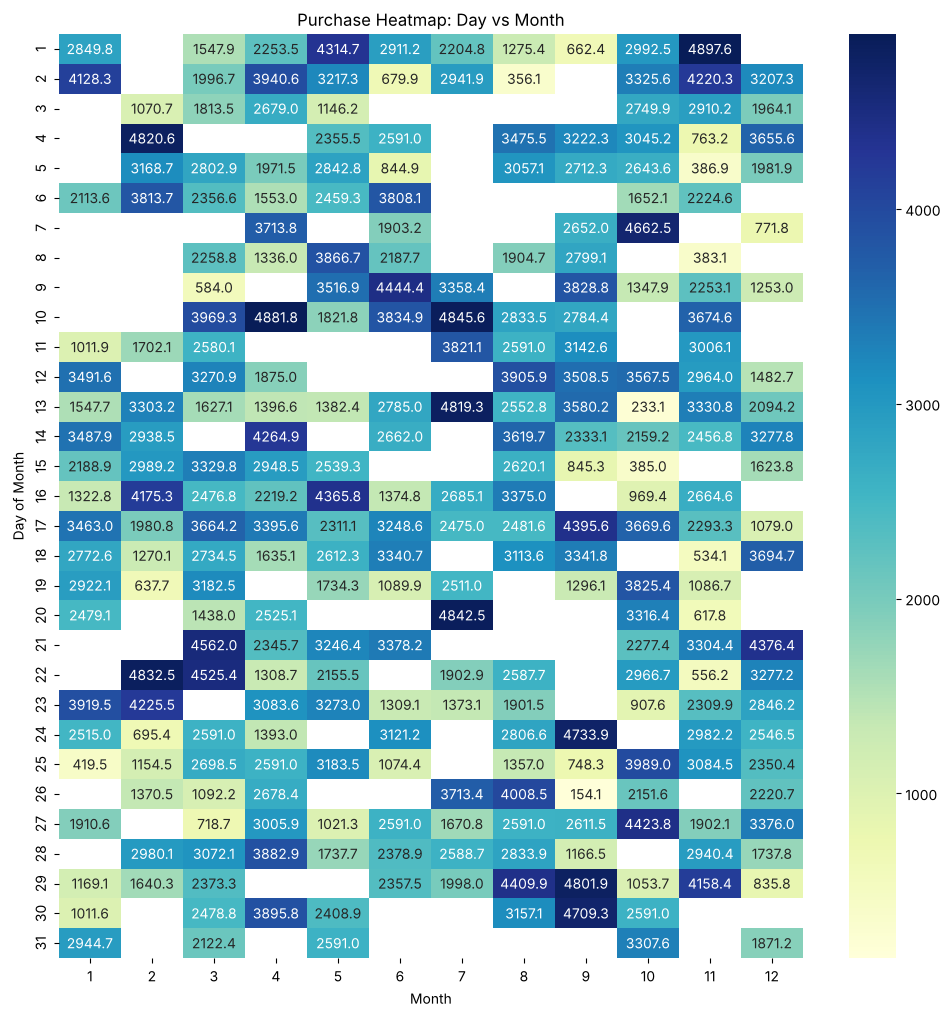

In [29]:
plt.figure(figsize=(12,12))
sns.heatmap(heatmap_data, cmap='YlGnBu', annot=True, fmt=".1f")
plt.xlabel("Month")
plt.ylabel("Day of Month")
plt.title("Purchase Heatmap: Day vs Month")
plt.show()


## 4. Recency and churn

Recency = days since a customer's last purchase, measured from the latest date in the data. A 90-day churn rule would flag 98% of customers here, which says more about the 3-year span of the data than about behaviour, so customers are grouped into three recency segments instead.

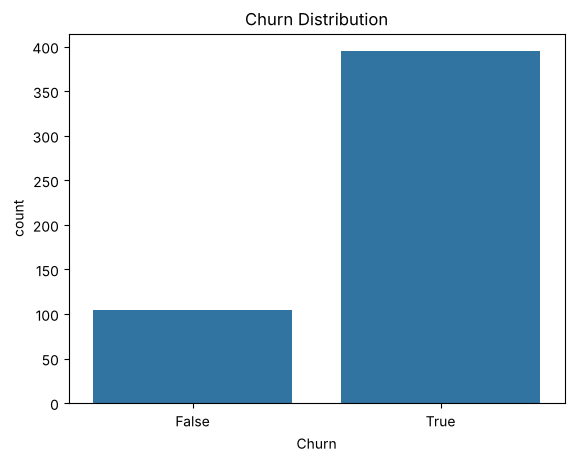

In [30]:
import datetime

# Get the most recent purchase date in the dataset
most_recent_purchase_date = df['Last_Purchase_Date'].max()

# Calculate Recency for each customer
df['Recency'] = (most_recent_purchase_date - df['Last_Purchase_Date']).dt.days

# 90 days flags 98% of customers in a dataset spanning 3+ years,
# so a customer counts as churned after a year without a purchase
df['Churn'] = df['Recency'] > 365

sns.countplot(x='Churn', data=df)
plt.title('Churn Distribution')
plt.show()

In [31]:
# Recency segments: how many customers are still active, and how much spend sits in each group
df['Segment'] = pd.cut(df['Recency'], bins=[-1, 180, 365, df['Recency'].max()],
                       labels=['Active (≤180 days)', 'At risk (181–365 days)', 'Lapsed (>365 days)'])
segments = df.groupby('Segment', observed=True).agg(
    customers=('User_ID', 'count'),
    total_spend=('Purchase_Amount', 'sum'),
    avg_spend=('Purchase_Amount', 'mean'),
    avg_feedback=('Feedback_Score', 'mean'),
)
segments['share_of_customers_%'] = (segments['customers'] / segments['customers'].sum() * 100).round(1)
segments.round(1)

,customers,total_spend,avg_spend,avg_feedback,share_of_customers_%
Segment,,,,,
Active (≤180 days),30,75540.0,2518.0,2.9,6.0
At risk (181–365 days),75,197943.9,2639.3,2.8,15.0
Lapsed (>365 days),395,1002991.5,2539.2,3.0,79.0


<Axes: xlabel='Churn', ylabel='Customer_Lifetime'>

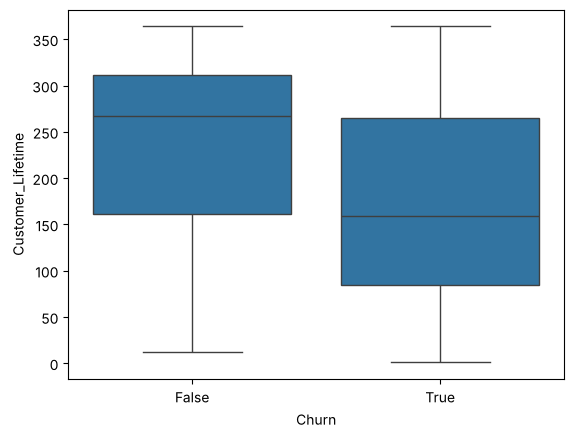

In [32]:
df['Customer_Lifetime'] = (df['Last_Purchase_Date'] - df['Signup_Date']).dt.days
sns.boxplot(x='Churn', y='Customer_Lifetime', data=df)

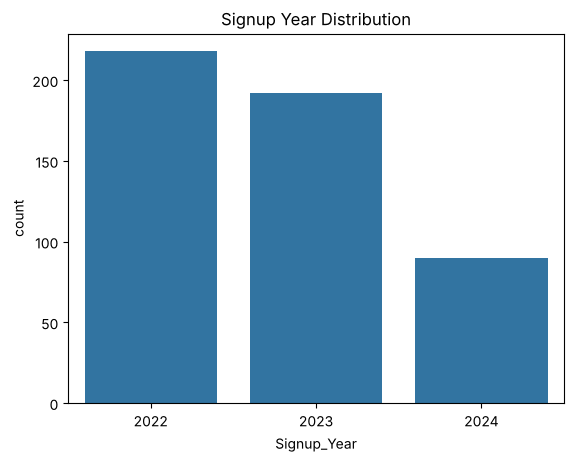

In [33]:
sns.countplot(x='Signup_Year', data=df)
plt.title('Signup Year Distribution')
plt.show()

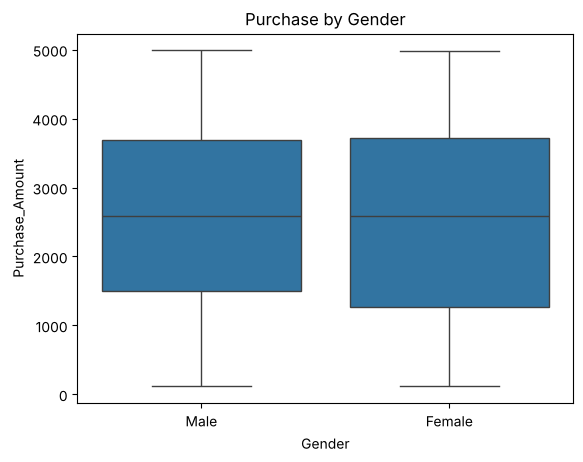

In [34]:
sns.boxplot(x='Gender', y='Purchase_Amount', data=df)
plt.title('Purchase by Gender')
plt.show()

## 5. Findings and recommendations

- **Most customers have lapsed.** 79% (395) haven't bought in over a year; only 6% (30) bought in the last 180 days.
- **The at-risk group is the opportunity.** 75 customers (15%) last bought 6–12 months ago and account for about ₹1.98 lakh of spend. They are recent enough for a win-back offer to work.
- **Lapsing isn't explained by spend or satisfaction.** Average spend (₹2,500–2,650) and feedback (2.8–3.0 out of 5) are almost identical across segments, so retention needs a reason to return (reminders, offers), not just better service.
- **Feedback is middling everywhere.** The average score is 2.9 out of 5, which is worth investigating on its own.
- **Spend is evenly spread** across Electronics, Home Decor, Groceries and Clothing, and across the five cities.

**Next steps:** run a targeted win-back campaign for the at-risk segment and track how many return within 60 days; collect purchase frequency (not just the last purchase) to build a proper RFM model.